# 3.7a Subject/background sharpness example

Compare an illustrated textured subject and a smooth background, then blur the image.
No detector/model download is needed. This example demonstrates detail sensitivity, not
clinical certainty about focus or visual dominance.

In [5]:
import json

import numpy as np
from IPython.display import display
from PIL import Image, ImageFilter

from brandlens.analysis.analysis_input import AnalysisInput
from brandlens.analysis.subject.region import SubjectRegion
from brandlens.analysis.subject_sharpness_criterion import SubjectSharpnessCriterion


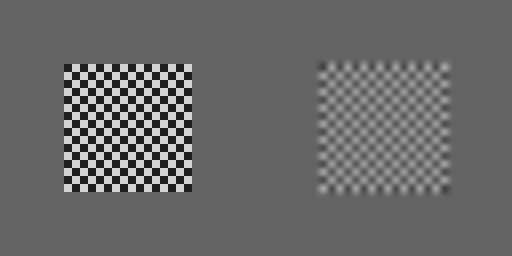

Original (left), Gaussian-blurred (right)


In [6]:
size = 256
pixels = np.full((size, size, 3), 100, dtype=np.uint8)
y, x = np.indices((128, 128))
texture = (((x // 8 + y // 8) % 2) * 180 + 30).astype(np.uint8)
pixels[64:192, 64:192] = texture[..., None]
image = Image.fromarray(pixels)
blurred = image.filter(ImageFilter.GaussianBlur(radius=3))
comparison = Image.new("RGB", (size * 2, size))
comparison.paste(image, (0, 0))
comparison.paste(blurred, (size, 0))
display(comparison)
print("Original (left), Gaussian-blurred (right)")
subject = SubjectRegion(.25, .25, .75, .75, reliable=True,
                        source="manual_demo", source_version="1")

In [7]:
criterion = SubjectSharpnessCriterion({"min_region_pixels": 16})
for name, photo in (("original", image), ("blurred", blurred)):
    result = criterion.analyze(AnalysisInput(photo, subject))
    print(name)
    print(json.dumps(result["measurements"], indent=2))

original
{
  "image_width": 256,
  "image_height": 256,
  "subject_sample_pixels": 15876,
  "subject_laplacian_variance": 19102.04081632653,
  "background_sample_pixels": 47616,
  "background_laplacian_variance": 0.0,
  "detail_emphasis_index": 1.0
}
blurred
{
  "image_width": 256,
  "image_height": 256,
  "subject_sample_pixels": 15876,
  "subject_laplacian_variance": 30.348897835778306,
  "background_sample_pixels": 47616,
  "background_laplacian_variance": 0.17190581749651332,
  "detail_emphasis_index": 0.9887351709706329
}


The four-neighbor Laplacian responds to local intensity changes. We use population
variance of its responses and omit image/region boundary neighborhoods.

`detail_emphasis_index = (subject variance - background variance) / (their sum)`.
Positive means more detail in the subject box. A high index alone does not establish
sharp focus: compare the absolute variances too. Noise and texture also affect them.
Measurements depend on resolution, so use a consistent preprocessing policy.

In [8]:
flat = Image.new("RGB", (size, size), (100, 100, 100))
result = criterion.analyze(AnalysisInput(flat, subject))
print(json.dumps(result, indent=2))

{
  "schema_version": "1.0.0",
  "criterion_id": "sharpness",
  "status": "unavailable_needs_review",
  "measurements": {
    "image_width": 256,
    "image_height": 256,
    "subject_sample_pixels": 15876,
    "subject_laplacian_variance": 0.0,
    "background_sample_pixels": 47616,
    "background_laplacian_variance": 0.0,
    "detail_emphasis_index": null
  },
  "method": {
    "id": "subject_box_laplacian_variance_4_neighbor",
    "version": "1",
    "parameters": {
      "min_region_pixels": 16
    }
  },
  "units": {
    "image_width": "pixels",
    "image_height": "pixels",
    "subject_sample_pixels": "pixels",
    "subject_laplacian_variance": "intensity_squared",
    "background_sample_pixels": "pixels",
    "background_laplacian_variance": "intensity_squared",
    "detail_emphasis_index": "dimensionless"
  },
  "reasons": [
    "Both regions have zero Laplacian variance; emphasis is undefined."
  ],
  "subject_region": {
    "left": 0.25,
    "top": 0.25,
    "right": 0.75,


Both flat regions have zero variance. Their relative emphasis is undefined and returns
`None` with a review reason. Bounding boxes approximate subject masks and may contain
background. No input enhancement or brand scoring occurs here.